In [1]:
import sys
import subprocess

packages = [
    "transformers==5.24.0",
    "huggingface-hub==1.33.0",
    "accelerate==1.15.0",
    "datasets==4.8.5",
    "pandas==2.2.3",
    "scikit-learn==1.6.1",
    "jedi==0.19.2"
]

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", *packages],
    check=True
)

import transformers
import huggingface_hub

print("Transformers loaded:", transformers.__version__)
print("Hub loaded:", huggingface_hub.__version__)

assert transformers.__version__ == "5.24.0"
assert huggingface_hub.__version__ == "1.33.0"

print("Environment imports are consistent.")

Transformers loaded: 5.24.0
Hub loaded: 1.33.0
Environment imports are consistent.


In [2]:
import random
import numpy as np
import pandas as pd
import torch

from importlib.metadata import version

SEED = 42

if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime before continuing.")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

device = torch.device("cuda")
gpu = torch.cuda.get_device_properties(device)

print(f"Python: {sys.version.split()[0]}")
print(f"GPU: {gpu.name}")
print(f"GPU memory: {gpu.total_memory / 1024**3:.1f} GB")
print(f"Random seed: {SEED}")

for package in ["torch", "numpy", "pandas", "datasets", "scikit-learn", "accelerate"]:
    print(f"{package}: {version(package)}")

Python: 3.13.16
GPU: Tesla T4
GPU memory: 14.6 GB
Random seed: 42
torch: 2.14.1+cu130
numpy: 2.4.6
pandas: 2.2.3
datasets: 4.8.5
scikit-learn: 1.6.1
accelerate: 1.15.0


In [3]:
import io
import json

from zipfile import ZipFile
from google.colab import files

uploaded = files.upload()
assert len(uploaded) == 1, "Upload only m3_data_setup.zip."

archive_name, archive_bytes = next(iter(uploaded.items()))

with ZipFile(io.BytesIO(archive_bytes)) as archive:
    required_files = {
        "split_manifest.json",
        "split_counts.csv",
        "split_overlap.csv"
    }
    assert required_files.issubset(archive.namelist())

    split_manifest = json.loads(archive.read("split_manifest.json"))
    saved_split_counts = pd.read_csv(archive.open("split_counts.csv"))
    saved_split_overlap = pd.read_csv(archive.open("split_overlap.csv"))

DATASET_NAME = split_manifest["dataset"]
DATASET_REVISION = split_manifest["dataset_revision"]
LABELS = split_manifest["labels"]

assert DATASET_NAME == "cnamuangtoun/resume-job-description-fit"
assert split_manifest["seed"] == SEED
assert LABELS == ["Good Fit", "Potential Fit", "No Fit"]

LABEL2ID = {label: index for index, label in enumerate(LABELS)}
ID2LABEL = {index: label for label, index in LABEL2ID.items()}

print(f"Archive: {archive_name}")
print(f"Dataset revision: {DATASET_REVISION}")
print(f"Label mapping: {LABEL2ID}")

display(saved_split_counts)

Saving m3_data_setup.zip to m3_data_setup.zip
Archive: m3_data_setup.zip
Dataset revision: 08978e21714984bb417547d2c0f9b477f5298163
Label mapping: {'Good Fit': 0, 'Potential Fit': 1, 'No Fit': 2}


,Split,Good Fit,Potential Fit,No Fit,Total,Unique jobs
0,Training,1258,1223,2600,5081,229
1,Validation,280,331,536,1147,51
2,Official test,458,444,857,1759,71


In [4]:
from datasets import load_dataset

REQUIRED_COLUMNS = ["resume_text", "job_description_text", "label"]

dataset = load_dataset(DATASET_NAME, revision=DATASET_REVISION)

source_frames = {
    name: dataset[name].to_pandas()[REQUIRED_COLUMNS]
    for name in ["train", "test"]
}

split_frames = {}

for split_name, row_ids in split_manifest["source_row_ids"].items():
    source_name = split_manifest["source_splits"][split_name]
    source_df = source_frames[source_name]

    assert len(row_ids) == len(set(row_ids))
    assert all(0 <= row_id < len(source_df) for row_id in row_ids)

    dataframe = source_df.iloc[row_ids].copy()
    dataframe["source_row_id"] = row_ids
    split_frames[split_name] = dataframe.reset_index(drop=True)

train_df = split_frames["Training"]
validation_df = split_frames["Validation"]
test_df = split_frames["Official test"]

actual_split_counts = pd.DataFrame({
    name: dataframe["label"].value_counts()
    for name, dataframe in split_frames.items()
}).reindex(LABELS).fillna(0).astype(int).T

actual_split_counts["Total"] = actual_split_counts.sum(axis=1)
expected_counts = saved_split_counts.set_index("Split")[LABELS + ["Total"]]

display(actual_split_counts)
assert actual_split_counts.equals(expected_counts)

print("All splits match the saved row and class counts.")

train.csv: reconstructing file:   0%|          |  0.00B / 53.4MB            

train.csv: downloading bytes:           |  0.00B            

test.csv: reconstructing file:   0%|          |  0.00B / 15.2MB            

test.csv: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

label,Good Fit,Potential Fit,No Fit,Total
Training,1258,1223,2600,5081
Validation,280,331,536,1147
Official test,458,444,857,1759


All splits match the saved row and class counts.


In [5]:
import re
import hashlib
import unicodedata

EMAIL_PATTERN = re.compile(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b")
URL_PATTERN = re.compile(r"(?:https?://|www\.)\S+", re.IGNORECASE)
PHONE_PATTERN = re.compile(r"(?<!\w)(?:\+?\d[\d\s().-]{8,}\d)(?!\w)")


def prepare_text(text):
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"\[([^\]]+)\]\([^)]+\)", r"\1", text)
    text = EMAIL_PATTERN.sub(" email ", text)
    text = URL_PATTERN.sub(" url ", text)
    text = PHONE_PATTERN.sub(
        lambda match: " phone "
        if sum(character.isdigit() for character in match.group()) >= 10
        else match.group(),
        text
    )
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[^\S\n]+", " ", text)
    return re.sub(r"\n\s*\n+", "\n", text).strip()


def text_group_id(text):
    normalized = " ".join(text.casefold().split())
    return hashlib.sha256(normalized.encode("utf-8")).hexdigest()


assert prepare_text("Skills: C++, C#, .NET") == "Skills: C++, C#, .NET"
print("Text preparation functions are ready.")

Text preparation functions are ready.


In [6]:
def prepare_frame(dataframe):
    result = dataframe.copy()
    result["resume_model_text"] = result["resume_text"].map(prepare_text)
    result["job_model_text"] = result["job_description_text"].map(prepare_text)
    result["resume_group"] = result["resume_model_text"].map(text_group_id)
    result["job_group"] = result["job_model_text"].map(text_group_id)
    result["labels"] = result["label"].map(LABEL2ID)

    assert result["labels"].notna().all()
    result["labels"] = result["labels"].astype("int64")
    return result


split_frames = {
    name: prepare_frame(dataframe)
    for name, dataframe in split_frames.items()
}

train_df = split_frames["Training"]
validation_df = split_frames["Validation"]
test_df = split_frames["Official test"]

MODEL_PAIR_COLUMNS = ["resume_group", "job_group"]
preparation_rows = []

for name, dataframe in split_frames.items():
    preparation_rows.append({
        "Split": name,
        "Rows": len(dataframe),
        "Unique jobs": dataframe["job_group"].nunique(),
        "Empty resumes": int(dataframe["resume_model_text"].eq("").sum()),
        "Empty jobs": int(dataframe["job_model_text"].eq("").sum()),
        "Duplicate pairs": int(dataframe.duplicated(MODEL_PAIR_COLUMNS).sum())
    })
    assert set(dataframe["labels"]) == set(ID2LABEL)

preparation_report = pd.DataFrame(preparation_rows)
display(preparation_report)

assert preparation_report[
    ["Empty resumes", "Empty jobs", "Duplicate pairs"]
].to_numpy().sum() == 0

assert preparation_report.set_index("Split")["Unique jobs"].equals(
    saved_split_counts.set_index("Split")["Unique jobs"]
)

,Split,Rows,Unique jobs,Empty resumes,Empty jobs,Duplicate pairs
0,Training,5081,229,0,0,0
1,Validation,1147,51,0,0,0
2,Official test,1759,71,0,0,0


In [7]:
from itertools import combinations

overlap_rows = []

for (first_name, first_df), (second_name, second_df) in combinations(
    split_frames.items(), 2
):
    first_pairs = set(
        first_df[MODEL_PAIR_COLUMNS].itertuples(index=False, name=None)
    )
    second_pairs = set(
        second_df[MODEL_PAIR_COLUMNS].itertuples(index=False, name=None)
    )

    overlap_rows.append({
        "Comparison": f"{first_name} / {second_name}",
        "Shared jobs": len(
            set(first_df["job_group"]) & set(second_df["job_group"])
        ),
        "Shared resumes": len(
            set(first_df["resume_group"]) & set(second_df["resume_group"])
        ),
        "Shared pairs": len(first_pairs & second_pairs)
    })

split_overlap_report = pd.DataFrame(overlap_rows)
display(split_overlap_report)

assert split_overlap_report.equals(saved_split_overlap)
assert split_overlap_report["Shared jobs"].eq(0).all()
assert split_overlap_report["Shared pairs"].eq(0).all()

print("Reconstructed splits match Vikas's saved overlap report exactly.")

,Comparison,Shared jobs,Shared resumes,Shared pairs
0,Training / Validation,0,429,0
1,Training / Official test,0,473,0
2,Validation / Official test,0,357,0


Reconstructed splits match Vikas's saved overlap report exactly.


In [8]:
from transformers import AutoTokenizer, DataCollatorWithPadding
from huggingface_hub import HfApi

MODEL_CHECKPOINTS = {
    "MiniLM": "microsoft/MiniLM-L12-H384-uncased",
    "DistilBERT": "distilbert/distilbert-base-uncased"
}

MAX_LENGTH = 512
tokenizers = {}
model_revisions = {}
tokenizer_rows = []

api = HfApi()

for name, checkpoint in MODEL_CHECKPOINTS.items():
    revision = api.model_info(checkpoint).sha
    tokenizer = AutoTokenizer.from_pretrained(checkpoint, revision=revision)

    assert tokenizer.pad_token_id is not None
    assert MAX_LENGTH <= tokenizer.model_max_length

    tokenizers[name] = tokenizer
    model_revisions[name] = revision

    tokenizer_rows.append({
        "Model": name,
        "Tokenizer": type(tokenizer).__name__,
        "Vocabulary size": len(tokenizer),
        "Model input limit": tokenizer.model_max_length,
        "Pair special tokens": tokenizer.num_special_tokens_to_add(pair=True)
    })

display(pd.DataFrame(tokenizer_rows))

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

,Model,Tokenizer,Vocabulary size,Model input limit,Pair special tokens
0,MiniLM,BertTokenizer,30522,1000000000000000019884624838656,3
1,DistilBERT,BertTokenizer,30522,512,3


In [9]:
from transformers import AutoConfig

model_configs = {}
input_limit_rows = []

for name, checkpoint in MODEL_CHECKPOINTS.items():
    config = AutoConfig.from_pretrained(
        checkpoint,
        revision=model_revisions[name]
    )

    actual_limit = config.max_position_embeddings
    assert MAX_LENGTH <= actual_limit

    model_configs[name] = config
    tokenizers[name].model_max_length = actual_limit

    input_limit_rows.append({
        "Model": name,
        "Architecture": config.model_type,
        "Actual input limit": actual_limit,
        "Selected input limit": MAX_LENGTH,
        "Uses token type IDs": config.model_type == "bert"
    })

display(pd.DataFrame(input_limit_rows))

,Model,Architecture,Actual input limit,Selected input limit,Uses token type IDs
0,MiniLM,bert,512,512,True
1,DistilBERT,distilbert,512,512,False


In [10]:
unique_texts = pd.concat([
    split_frames[split_name][column]
    for split_name in ["Training", "Validation"]
    for column in ["resume_model_text", "job_model_text"]
]).drop_duplicates().tolist()

length_data = {}
length_rows = []

for name, tokenizer in tokenizers.items():
    encoded = tokenizer(
        unique_texts,
        add_special_tokens=False,
        truncation=False,
        padding=False,
        return_attention_mask=False,
        return_token_type_ids=False,
        verbose=False
    )

    text_lengths = {
        text: len(ids)
        for text, ids in zip(unique_texts, encoded["input_ids"])
    }
    del encoded

    length_data[name] = {}

    for split_name in ["Training", "Validation"]:
        dataframe = split_frames[split_name]
        resume_lengths = dataframe["resume_model_text"].map(text_lengths).to_numpy()
        job_lengths = dataframe["job_model_text"].map(text_lengths).to_numpy()
        pair_lengths = (
            resume_lengths + job_lengths
            + tokenizer.num_special_tokens_to_add(pair=True)
        )

        length_data[name][split_name] = {
            "resume": resume_lengths,
            "job": job_lengths,
            "pair": pair_lengths
        }

        length_rows.append({
            "Model": name,
            "Split": split_name,
            "Mean resume tokens": round(resume_lengths.mean(), 1),
            "Mean job tokens": round(job_lengths.mean(), 1),
            "Median pair tokens": round(float(np.median(pair_lengths)), 1),
            "Pairs over 512 (%)": round(float((pair_lengths > MAX_LENGTH).mean() * 100), 2)
        })

length_report = pd.DataFrame(length_rows)
display(length_report)

,Model,Split,Mean resume tokens,Mean job tokens,Median pair tokens,Pairs over 512 (%)
0,MiniLM,Training,1153.7,530.9,1576.0,99.63
1,MiniLM,Validation,1169.9,404.0,1443.0,99.39
2,DistilBERT,Training,1153.7,530.9,1576.0,99.63
3,DistilBERT,Validation,1169.9,404.0,1443.0,99.39


In [11]:
from datasets import Dataset, DatasetDict

TRUNCATION_POLICY = "longest_first"


def tokenize_pairs(batch, tokenizer, use_token_type_ids):
    return tokenizer(
        batch["resume_model_text"],
        batch["job_model_text"],
        truncation=TRUNCATION_POLICY,
        max_length=MAX_LENGTH,
        padding=False,
        return_attention_mask=True,
        return_token_type_ids=use_token_type_ids
    )


tokenized_datasets = {}

for name, tokenizer in tokenizers.items():
    tokenizer.truncation_side = "right"
    tokenized_datasets[name] = DatasetDict()

    for split_name, dataframe in split_frames.items():
        source_dataset = Dataset.from_pandas(
            dataframe[["resume_model_text", "job_model_text", "labels"]],
            preserve_index=False
        )

        tokenized_datasets[name][split_name] = source_dataset.map(
            tokenize_pairs,
            batched=True,
            batch_size=128,
            fn_kwargs={
                "tokenizer": tokenizer,
                "use_token_type_ids": model_configs[name].model_type == "bert"
            },
            remove_columns=["resume_model_text", "job_model_text"],
            desc=f"{name}: {split_name}"
        )

    print(name, {
        split: data.num_rows
        for split, data in tokenized_datasets[name].items()
    })
    print("Columns:", tokenized_datasets[name]["Training"].column_names)

MiniLM: Training:   0%|          | 0/5081 [00:00<?, ? examples/s]

MiniLM: Validation:   0%|          | 0/1147 [00:00<?, ? examples/s]

MiniLM: Official test:   0%|          | 0/1759 [00:00<?, ? examples/s]

MiniLM {'Training': 5081, 'Validation': 1147, 'Official test': 1759}
Columns: ['labels', 'input_ids', 'token_type_ids', 'attention_mask']


DistilBERT: Training:   0%|          | 0/5081 [00:00<?, ? examples/s]

DistilBERT: Validation:   0%|          | 0/1147 [00:00<?, ? examples/s]

DistilBERT: Official test:   0%|          | 0/1759 [00:00<?, ? examples/s]

DistilBERT {'Training': 5081, 'Validation': 1147, 'Official test': 1759}
Columns: ['labels', 'input_ids', 'attention_mask']


In [12]:
tokenization_rows = []

for name, model_splits in tokenized_datasets.items():
    expected_columns = {"labels", "input_ids", "attention_mask"}

    if model_configs[name].model_type == "bert":
        expected_columns.add("token_type_ids")

    special_tokens = tokenizers[name].num_special_tokens_to_add(pair=True)

    for split_name, data in model_splits.items():
        input_lengths = np.array([len(ids) for ids in data["input_ids"]])
        mask_lengths = np.array([len(mask) for mask in data["attention_mask"]])

        assert set(data.column_names) == expected_columns
        assert len(data) == len(split_frames[split_name])
        assert np.array_equal(input_lengths, mask_lengths)
        assert input_lengths.min() > special_tokens
        assert input_lengths.max() <= MAX_LENGTH
        assert np.array_equal(
            np.array(data["labels"]),
            split_frames[split_name]["labels"].to_numpy()
        )

        if "token_type_ids" in expected_columns:
            assert np.array_equal(
                input_lengths,
                np.array([len(ids) for ids in data["token_type_ids"]])
            )

        retention = None
        if split_name in length_data[name]:
            original_lengths = length_data[name][split_name]["pair"]
            retention = round(float(np.mean(
                (input_lengths - special_tokens)
                / (original_lengths - special_tokens) * 100
            )), 2)

        tokenization_rows.append({
            "Model": name,
            "Split": split_name,
            "Rows": len(data),
            "Minimum tokens": int(input_lengths.min()),
            "Maximum tokens": int(input_lengths.max()),
            "Mean tokens retained (%)": retention
        })

tokenization_report = pd.DataFrame(tokenization_rows)
display(tokenization_report)

,Model,Split,Rows,Minimum tokens,Maximum tokens,Mean tokens retained (%)
0,MiniLM,Training,5081,334,512,34.76
1,MiniLM,Validation,1147,437,512,37.84
2,MiniLM,Official test,1759,409,512,NaN
3,DistilBERT,Training,5081,334,512,34.76
4,DistilBERT,Validation,1147,437,512,37.84
5,DistilBERT,Official test,1759,409,512,NaN


In [13]:
collators = {}
batch_rows = []

for name, tokenizer in tokenizers.items():
    collator = DataCollatorWithPadding(
        tokenizer=tokenizer,
        padding=True,
        pad_to_multiple_of=8,
        return_tensors="pt"
    )
    collators[name] = collator

    training_data = tokenized_datasets[name]["Training"]
    lengths = np.array([len(ids) for ids in training_data["input_ids"]])
    sorted_indices = np.argsort(lengths)
    sample_indices = np.concatenate(
        [sorted_indices[:4], sorted_indices[-4:]]
    ).tolist()

    features = [training_data[index] for index in sample_indices]
    batch = collator(features)
    padding_positions = batch["attention_mask"].eq(0)

    assert set(batch) == set(features[0])
    assert all(tensor.dtype == torch.long for tensor in batch.values())
    assert batch["input_ids"].shape == batch["attention_mask"].shape
    assert batch["labels"].tolist() == [item["labels"] for item in features]
    assert batch["attention_mask"].sum(dim=1).tolist() == [
        len(item["input_ids"]) for item in features
    ]
    assert padding_positions.any().item()
    assert batch["input_ids"][padding_positions].eq(tokenizer.pad_token_id).all().item()

    batch_rows.append({
        "Model": name,
        "Input shape": str(tuple(batch["input_ids"].shape)),
        "Padding tokens": int(padding_positions.sum().item()),
        "Label dtype": str(batch["labels"].dtype)
    })

batch_report = pd.DataFrame(batch_rows)
display(batch_report)

,Model,Input shape,Padding tokens,Label dtype
0,MiniLM,"(8, 512)",475,torch.int64
1,DistilBERT,"(8, 512)",475,torch.int64


In [14]:
from pathlib import Path
from importlib.metadata import version

OUTPUT_DIR = Path("/content/m3_tokenization")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

tokenization_config = {
    "dataset": DATASET_NAME,
    "dataset_revision": DATASET_REVISION,
    "python_version": sys.version.split()[0],
    "seed": SEED,
    "max_length": MAX_LENGTH,
    "truncation": TRUNCATION_POLICY,
    "truncation_side": "right",
    "padding": "dynamic",
    "pad_to_multiple_of": 8,
    "pair_order": ["resume_model_text", "job_model_text"],
    "label2id": LABEL2ID,
    "checkpoints": MODEL_CHECKPOINTS,
    "model_revisions": model_revisions,
    "token_type_ids": {
        name: config.model_type == "bert"
        for name, config in model_configs.items()
    },
    "package_versions": {
        package: version(package)
        for package in [
            "transformers", "huggingface-hub", "tokenizers", "accelerate",
            "datasets", "numpy", "pandas", "scikit-learn", "torch"
        ]
    }
}

(OUTPUT_DIR / "tokenization_config.json").write_text(
    json.dumps(tokenization_config, indent=2), encoding="utf-8"
)
(OUTPUT_DIR / "split_manifest.json").write_text(
    json.dumps(split_manifest, indent=2), encoding="utf-8"
)

length_report.to_csv(OUTPUT_DIR / "input_lengths.csv", index=False)
tokenization_report.to_csv(OUTPUT_DIR / "tokenization_report.csv", index=False)
batch_report.to_csv(OUTPUT_DIR / "batch_report.csv", index=False)

for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size:,} bytes")

batch_report.csv: 117 bytes
input_lengths.csv: 265 bytes
split_manifest.json: 94,346 bytes
tokenization_config.json: 1,076 bytes
tokenization_report.csv: 298 bytes


In [15]:
from zipfile import ZipFile, ZIP_DEFLATED

saved_config = json.loads(
    (OUTPUT_DIR / "tokenization_config.json").read_text(encoding="utf-8")
)
saved_manifest = json.loads(
    (OUTPUT_DIR / "split_manifest.json").read_text(encoding="utf-8")
)

assert saved_config == tokenization_config
assert saved_manifest == split_manifest

for filename, expected_report in [
    ("input_lengths.csv", length_report),
    ("tokenization_report.csv", tokenization_report),
    ("batch_report.csv", batch_report)
]:
    pd.testing.assert_frame_equal(
        pd.read_csv(OUTPUT_DIR / filename),
        expected_report,
        check_exact=False,
        rtol=1e-12,
        atol=1e-12
    )

export_files = [
    "tokenization_config.json",
    "split_manifest.json",
    "input_lengths.csv",
    "tokenization_report.csv",
    "batch_report.csv"
]

archive_path = Path("/content/m3_tokenization_setup.zip")

with ZipFile(archive_path, "w", ZIP_DEFLATED) as archive:
    for filename in export_files:
        archive.write(OUTPUT_DIR / filename, arcname=filename)

print("Configuration, split identifiers, and all reports verified.")
print(f"Archive: {archive_path.name}")
files.download(str(archive_path))

Configuration, split identifiers, and all reports verified.
Archive: m3_tokenization_setup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
from transformers import AutoModelForSequenceClassification, set_seed

set_seed(SEED)

MODEL_NAME = "MiniLM"

minilm_tokenizer = tokenizers[MODEL_NAME]
minilm_data = tokenized_datasets[MODEL_NAME]
minilm_collator = collators[MODEL_NAME]

minilm_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINTS[MODEL_NAME],
    revision=model_revisions[MODEL_NAME],
    num_labels=len(LABEL2ID),
    label2id=LABEL2ID,
    id2label=ID2LABEL
).to(device)

total_parameters = sum(
    parameter.numel() for parameter in minilm_model.parameters()
)
trainable_parameters = sum(
    parameter.numel()
    for parameter in minilm_model.parameters()
    if parameter.requires_grad
)

assert minilm_model.config.num_labels == 3
assert trainable_parameters == total_parameters

print(f"Checkpoint: {MODEL_CHECKPOINTS[MODEL_NAME]}")
print(f"Revision: {model_revisions[MODEL_NAME]}")
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Labels: {minilm_model.config.id2label}")
print(f"GPU memory allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  133MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/MiniLM-L12-H384-uncased
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Checkpoint: microsoft/MiniLM-L12-H384-uncased
Revision: 44acabbec0ef496f6dbc93adadea57f376b7c0ec
Total parameters: 33,361,155
Trainable parameters: 33,361,155
Labels: {0: 'Good Fit', 1: 'Potential Fit', 2: 'No Fit'}
GPU memory allocated: 0.12 GB


In [17]:
features = [minilm_data["Training"][index] for index in range(8)]

check_batch = {
    key: tensor.to(device)
    for key, tensor in minilm_collator(features).items()
}

minilm_model.eval()

with torch.inference_mode():
    check_output = minilm_model(**check_batch)

assert check_output.logits.shape == (8, len(LABEL2ID))
assert check_output.loss.ndim == 0
assert torch.isfinite(check_output.logits).all().item()
assert torch.isfinite(check_output.loss).item()

print("Batch shapes:", {
    key: tuple(tensor.shape)
    for key, tensor in check_batch.items()
})
print("Logits shape:", tuple(check_output.logits.shape))
print(f"Initial diagnostic loss: {check_output.loss.item():.4f}")
print("Forward-pass checks passed. No weights were updated.")

minilm_model.train()

del check_batch, check_output
torch.cuda.empty_cache()

Batch shapes: {'labels': (8,), 'input_ids': (8, 512), 'token_type_ids': (8, 512), 'attention_mask': (8, 512)}
Logits shape: (8, 3)
Initial diagnostic loss: 1.0516
Forward-pass checks passed. No weights were updated.


In [18]:
import math
from sklearn.metrics import accuracy_score, f1_score, recall_score

NUM_EPOCHS = 3
BATCH_SIZE = 8
GRAD_ACCUMULATION = 2
LEARNING_RATE = 2e-5


def compute_metrics(prediction):
    true_labels = prediction.label_ids
    predicted_labels = prediction.predictions.argmax(axis=-1)
    label_ids = list(ID2LABEL)

    metrics = {
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "macro_f1": f1_score(
            true_labels, predicted_labels,
            labels=label_ids, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            true_labels, predicted_labels,
            labels=label_ids, average="weighted", zero_division=0
        )
    }

    recalls = recall_score(
        true_labels, predicted_labels,
        labels=label_ids, average=None, zero_division=0
    )

    metrics.update({
        f"recall_{ID2LABEL[index].lower().replace(' ', '_')}": float(value)
        for index, value in zip(label_ids, recalls)
    })
    return metrics


updates_per_epoch = math.ceil(
    math.ceil(len(minilm_data["Training"]) / BATCH_SIZE) / GRAD_ACCUMULATION
)

print(f"Maximum epochs: {NUM_EPOCHS}")
print(f"Effective batch size: {BATCH_SIZE * GRAD_ACCUMULATION}")
print(f"Optimizer updates per epoch: {updates_per_epoch}")
print(f"Maximum optimizer updates: {updates_per_epoch * NUM_EPOCHS}")

Maximum epochs: 3
Effective batch size: 16
Optimizer updates per epoch: 318
Maximum optimizer updates: 954


In [19]:
import time
from torch.utils.data import DataLoader

WARMUP_STEPS = 3
BENCHMARK_STEPS = 20

benchmark_loader = DataLoader(
    minilm_data["Training"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=minilm_collator,
    pin_memory=True
)

step_times = []
minilm_model.train()
minilm_model.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats()

with torch.random.fork_rng(devices=[torch.cuda.current_device()]):
    iterator = iter(benchmark_loader)

    for step in range(WARMUP_STEPS + BENCHMARK_STEPS):
        torch.cuda.synchronize()
        started = time.perf_counter()

        benchmark_batch = {
            key: tensor.to(device, non_blocking=True)
            for key, tensor in next(iterator).items()
        }

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            benchmark_loss = minilm_model(**benchmark_batch).loss
            benchmark_loss = benchmark_loss / GRAD_ACCUMULATION

        assert torch.isfinite(benchmark_loss).item()
        benchmark_loss.backward()
        minilm_model.zero_grad(set_to_none=True)

        torch.cuda.synchronize()
        if step >= WARMUP_STEPS:
            step_times.append(time.perf_counter() - started)

mean_step_seconds = float(np.mean(step_times))
batches_per_epoch = math.ceil(len(minilm_data["Training"]) / BATCH_SIZE)
estimated_minutes = mean_step_seconds * batches_per_epoch * NUM_EPOCHS / 60

print(f"Mean batch time: {mean_step_seconds:.3f} seconds")
print(f"Estimated forward/backward time for 3 epochs: {estimated_minutes:.1f} minutes")
print(f"Peak GPU allocation: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")
print("Benchmark finished. No optimizer steps or weight updates were performed.")

del benchmark_batch, benchmark_loss, benchmark_loader, iterator
torch.cuda.empty_cache()

Mean batch time: 0.102 seconds
Estimated forward/backward time for 3 epochs: 3.3 minutes
Peak GPU allocation: 1.03 GB
Benchmark finished. No optimizer steps or weight updates were performed.


In [20]:
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback

MINILM_OUTPUT_DIR = "/content/m3_training/minilm"

training_args = TrainingArguments(
    output_dir=MINILM_OUTPUT_DIR,
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=GRAD_ACCUMULATION,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    warmup_steps=math.ceil(updates_per_epoch * NUM_EPOCHS * 0.1),
    lr_scheduler_type="linear",
    optim="adamw_torch",
    max_grad_norm=1.0,
    fp16=True,
    bf16=False,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_strategy="steps",
    logging_steps=25,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0
)

print(f"Output directory: {training_args.output_dir}")
print(f"Maximum epochs: {training_args.num_train_epochs}")
print(f"Warmup updates: {training_args.warmup_steps}")
print(f"Checkpoint selection: validation {training_args.metric_for_best_model}")
print("Training configuration is ready.")

Output directory: /content/m3_training/minilm
Maximum epochs: 3
Warmup updates: 96
Checkpoint selection: validation macro_f1
Training configuration is ready.


In [21]:
import time

minilm_trainer = Trainer(
    model=minilm_model,
    args=training_args,
    train_dataset=minilm_data["Training"],
    eval_dataset=minilm_data["Validation"],
    processing_class=minilm_tokenizer,
    data_collator=minilm_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=1)
    ]
)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

training_started = time.perf_counter()
minilm_train_result = minilm_trainer.train()

minilm_training_seconds = time.perf_counter() - training_started
minilm_peak_gpu_gb = torch.cuda.max_memory_allocated() / 1024**3

print(f"Training wall time: {minilm_training_seconds / 60:.2f} minutes")
print(f"Peak GPU allocation: {minilm_peak_gpu_gb:.2f} GB")
print(f"Optimizer updates: {minilm_trainer.state.global_step}")
print(f"Best validation macro-F1: {minilm_trainer.state.best_metric:.4f}")
print(f"Best checkpoint: {minilm_trainer.state.best_model_checkpoint}")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1,Recall Good Fit,Recall Potential Fit,Recall No Fit
1,2.058403,1.045825,0.467306,0.212319,0.297654,0.000000,0.000000,1.000000
2,1.898070,1.056039,0.468178,0.308137,0.372033,0.264286,0.000000,0.863806
3,1.807688,1.031183,0.466434,0.304239,0.369603,0.250000,0.000000,0.867537


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training wall time: 4.66 minutes
Peak GPU allocation: 1.42 GB
Optimizer updates: 954
Best validation macro-F1: 0.3081
Best checkpoint: /content/m3_training/minilm/checkpoint-636


In [22]:
from sklearn.metrics import classification_report, confusion_matrix

minilm_validation_output = minilm_trainer.predict(
    minilm_data["Validation"],
    metric_key_prefix="validation"
)

minilm_validation_predictions = (
    minilm_validation_output.predictions.argmax(axis=-1)
)
minilm_validation_labels = minilm_validation_output.label_ids

assert np.array_equal(
    minilm_validation_labels,
    validation_df["labels"].to_numpy()
)

report = classification_report(
    minilm_validation_labels,
    minilm_validation_predictions,
    labels=list(ID2LABEL),
    target_names=LABELS,
    output_dict=True,
    zero_division=0
)

minilm_class_report = pd.DataFrame(report).T.loc[
    LABELS, ["precision", "recall", "f1-score", "support"]
]
minilm_class_report["support"] = minilm_class_report["support"].astype(int)

minilm_confusion = pd.DataFrame(
    confusion_matrix(
        minilm_validation_labels,
        minilm_validation_predictions,
        labels=list(ID2LABEL)
    ),
    index=pd.Index(LABELS, name="True label"),
    columns=pd.Index(LABELS, name="Predicted label")
)

display(minilm_class_report.round(4))
display(minilm_confusion)

print(
    "Selected-checkpoint validation macro-F1:",
    round(minilm_validation_output.metrics["validation_macro_f1"], 4)
)

,precision,recall,f1-score,support
Good Fit,0.2731,0.2643,0.2686,280
Potential Fit,0.0000,0.0000,0.0000,331
No Fit,0.5285,0.8638,0.6558,536


Predicted label,Good Fit,Potential Fit,No Fit
True label,,,
Good Fit,74,0,206
Potential Fit,124,0,207
No Fit,73,0,463


Selected-checkpoint validation macro-F1: 0.3081


In [23]:
RUN_DIR = Path(MINILM_OUTPUT_DIR)
MODEL_EXPORT_DIR = RUN_DIR / "best_model"
REPORT_DIR = RUN_DIR / "reports"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

minilm_trainer.save_model(str(MODEL_EXPORT_DIR))

pd.DataFrame(minilm_trainer.state.log_history).to_csv(
    REPORT_DIR / "training_history.csv",
    index=False
)

minilm_class_report.to_csv(
    REPORT_DIR / "validation_class_report.csv",
    index_label="Class"
)

minilm_confusion.to_csv(
    REPORT_DIR / "validation_confusion_matrix.csv"
)

(REPORT_DIR / "validation_metrics.json").write_text(
    json.dumps(minilm_validation_output.metrics, indent=2, allow_nan=False),
    encoding="utf-8"
)

print(f"Selected model saved to: {MODEL_EXPORT_DIR}")
print("Validation reports:")

for path in sorted(REPORT_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size:,} bytes")

print("Model files:", sorted(path.name for path in MODEL_EXPORT_DIR.iterdir()))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Selected model saved to: /content/m3_training/minilm/best_model
Validation reports:
training_history.csv: 4,417 bytes
validation_class_report.csv: 209 bytes
validation_confusion_matrix.csv: 99 bytes
validation_metrics.json: 442 bytes
Model files: ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


In [24]:
minilm_run_summary = {
    "run_id": "minilm_v1",
    "model": MODEL_CHECKPOINTS["MiniLM"],
    "model_revision": model_revisions["MiniLM"],
    "dataset_revision": DATASET_REVISION,
    "seed": SEED,
    "loss": "unweighted cross-entropy",
    "split_rows": {
        name: len(dataframe)
        for name, dataframe in split_frames.items()
    },
    "best_checkpoint": Path(
        minilm_trainer.state.best_model_checkpoint
    ).name,
    "best_validation_macro_f1": float(minilm_trainer.state.best_metric),
    "optimizer_updates": minilm_trainer.state.global_step,
    "training_wall_seconds": minilm_training_seconds,
    "peak_gpu_allocated_gb": minilm_peak_gpu_gb,
    "validation_prediction_counts": {
        label: int((minilm_validation_predictions == label_id).sum())
        for label, label_id in LABEL2ID.items()
    },
    "official_test_evaluated": False
}

(REPORT_DIR / "run_summary.json").write_text(
    json.dumps(minilm_run_summary, indent=2, allow_nan=False),
    encoding="utf-8"
)

(REPORT_DIR / "training_arguments.json").write_text(
    training_args.to_json_string(),
    encoding="utf-8"
)

(REPORT_DIR / "tokenization_config.json").write_text(
    json.dumps(tokenization_config, indent=2),
    encoding="utf-8"
)

print(json.dumps(minilm_run_summary, indent=2))
print("Training arguments and tokenization configuration saved.")

{
  "run_id": "minilm_v1",
  "model": "microsoft/MiniLM-L12-H384-uncased",
  "model_revision": "44acabbec0ef496f6dbc93adadea57f376b7c0ec",
  "dataset_revision": "08978e21714984bb417547d2c0f9b477f5298163",
  "seed": 42,
  "loss": "unweighted cross-entropy",
  "split_rows": {
    "Training": 5081,
    "Validation": 1147,
    "Official test": 1759
  },
  "best_checkpoint": "checkpoint-636",
  "best_validation_macro_f1": 0.3081366354246464,
  "optimizer_updates": 954,
  "training_wall_seconds": 279.610189947,
  "peak_gpu_allocated_gb": 1.4233760833740234,
  "validation_prediction_counts": {
    "Good Fit": 271,
    "Potential Fit": 0,
    "No Fit": 876
  },
  "official_test_evaluated": false
}
Training arguments and tokenization configuration saved.


In [26]:
reloaded_tokenizer = AutoTokenizer.from_pretrained(
    str(MODEL_EXPORT_DIR),
    local_files_only=True
)

reloaded_model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_EXPORT_DIR),
    local_files_only=True
).to(device)

probe = ("Skills: Python, C++, C# and SQL.", "Requirements: Python and SQL.")
assert reloaded_tokenizer(*probe) == minilm_tokenizer(*probe)
assert reloaded_model.config.label2id == LABEL2ID
assert reloaded_model.config.id2label == ID2LABEL

original_state = minilm_trainer.model.state_dict()
reloaded_state = reloaded_model.state_dict()

assert original_state.keys() == reloaded_state.keys()

mismatched_tensors = [
    name
    for name in original_state
    if original_state[name].dtype != reloaded_state[name].dtype
    or not torch.equal(original_state[name], reloaded_state[name])
]

assert not mismatched_tensors, (
    f"Saved tensors differ: {mismatched_tensors[:5]}"
)

print(f"Tensors checked: {len(original_state)}")
print("All saved weights and persistent buffers match exactly.")
print("Tokenizer and label mappings also match.")

del original_state, reloaded_state

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Tensors checked: 201
All saved weights and persistent buffers match exactly.
Tokenizer and label mappings also match.


In [27]:
reload_features = [
    minilm_data["Validation"][index] for index in range(2)
]
reload_batch = {
    key: tensor.to(device)
    for key, tensor in minilm_collator(reload_features).items()
    if key != "labels"
}

minilm_trainer.model.eval()
reloaded_model.eval()

with torch.inference_mode(), torch.autocast(
    device_type="cuda", dtype=torch.float16
):
    original_logits = minilm_trainer.model(**reload_batch).logits.float()
    reloaded_logits = reloaded_model(**reload_batch).logits.float()

torch.testing.assert_close(
    original_logits, reloaded_logits, rtol=1e-4, atol=1e-5
)
assert torch.equal(
    original_logits.argmax(dim=-1),
    reloaded_logits.argmax(dim=-1)
)

reload_check = {
    "weights_match_exactly": True,
    "tokenizer_and_labels_match": True,
    "comparison_precision": "FP16 autocast",
    "validation_examples_checked": 2,
    "maximum_logit_difference": float(
        (original_logits - reloaded_logits).abs().max().item()
    ),
    "passed": True
}

(REPORT_DIR / "reload_check.json").write_text(
    json.dumps(reload_check, indent=2), encoding="utf-8"
)
print(json.dumps(reload_check, indent=2))

del reloaded_model, reloaded_tokenizer, reload_batch, reload_features
del original_logits, reloaded_logits
torch.cuda.empty_cache()

{
  "weights_match_exactly": true,
  "tokenizer_and_labels_match": true,
  "comparison_precision": "FP16 autocast",
  "validation_examples_checked": 2,
  "maximum_logit_difference": 0.0,
  "passed": true
}


In [28]:
from zipfile import ZipFile, ZIP_DEFLATED

assert json.loads(
    (REPORT_DIR / "reload_check.json").read_text()
)["passed"]

model_archive = Path("/content/minilm_v1_model.zip")
reports_archive = Path("/content/minilm_v1_reports.zip")

model_files = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json"
]

with ZipFile(model_archive, "w", ZIP_DEFLATED) as archive:
    for filename in model_files:
        archive.write(MODEL_EXPORT_DIR / filename, arcname=filename)

with ZipFile(reports_archive, "w", ZIP_DEFLATED) as archive:
    for path in sorted(REPORT_DIR.iterdir()):
        if path.is_file():
            archive.write(path, arcname=path.name)

for path in [reports_archive, model_archive]:
    with ZipFile(path) as archive:
        assert archive.testzip() is None
        print(f"{path.name}: {len(archive.namelist())} files")
    print(f"Size: {path.stat().st_size / 1024**2:.2f} MiB")

files.download(str(reports_archive))
files.download(str(model_archive))

minilm_v1_reports.zip: 8 files
Size: 0.01 MiB
minilm_v1_model.zip: 4 files
Size: 110.96 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
assert "tokenized_datasets" in globals(), (
    "Prepared datasets are missing. Do not rerun MiniLM training."
)

set_seed(SEED)

DISTILBERT_OUTPUT_DIR = "/content/m3_training/distilbert"

distilbert_tokenizer = tokenizers["DistilBERT"]
distilbert_data = tokenized_datasets["DistilBERT"]
distilbert_collator = collators["DistilBERT"]

assert all(
    "token_type_ids" not in data.column_names
    for data in distilbert_data.values()
)

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINTS["DistilBERT"],
    revision=model_revisions["DistilBERT"],
    num_labels=len(LABEL2ID),
    label2id=LABEL2ID,
    id2label=ID2LABEL
).to(device)

total_parameters = sum(
    parameter.numel() for parameter in distilbert_model.parameters()
)
trainable_parameters = sum(
    parameter.numel()
    for parameter in distilbert_model.parameters()
    if parameter.requires_grad
)

assert distilbert_model.config.model_type == "distilbert"
assert trainable_parameters == total_parameters

print(f"Checkpoint: {MODEL_CHECKPOINTS['DistilBERT']}")
print(f"Revision: {model_revisions['DistilBERT']}")
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Labels: {distilbert_model.config.id2label}")
print(f"GPU memory allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Checkpoint: distilbert/distilbert-base-uncased
Revision: 12040accade4e8a0f71eabdb258fecc2e7e948be
Total parameters: 66,955,779
Trainable parameters: 66,955,779
Labels: {0: 'Good Fit', 1: 'Potential Fit', 2: 'No Fit'}
GPU memory allocated: 0.65 GB


In [30]:
distilbert_features = [
    distilbert_data["Training"][index] for index in range(BATCH_SIZE)
]

distilbert_check_batch = {
    key: tensor.to(device)
    for key, tensor in distilbert_collator(distilbert_features).items()
}

assert set(distilbert_check_batch) == {
    "labels", "input_ids", "attention_mask"
}

distilbert_model.eval()

with torch.inference_mode():
    distilbert_check_output = distilbert_model(**distilbert_check_batch)

assert distilbert_check_output.logits.shape == (BATCH_SIZE, len(LABEL2ID))
assert distilbert_check_output.loss.ndim == 0
assert torch.isfinite(distilbert_check_output.logits).all().item()
assert torch.isfinite(distilbert_check_output.loss).item()

print("Batch shapes:", {
    key: tuple(tensor.shape)
    for key, tensor in distilbert_check_batch.items()
})
print("Logits shape:", tuple(distilbert_check_output.logits.shape))
print(f"Initial diagnostic loss: {distilbert_check_output.loss.item():.4f}")
print("Forward-pass checks passed. No weights were updated.")

distilbert_model.train()

del distilbert_check_batch, distilbert_check_output
torch.cuda.empty_cache()

Batch shapes: {'labels': (8,), 'input_ids': (8, 512), 'attention_mask': (8, 512)}
Logits shape: (8, 3)
Initial diagnostic loss: 1.1030
Forward-pass checks passed. No weights were updated.


In [31]:
minilm_trainer.model.to("cpu")

if minilm_trainer.optimizer is not None:
    for state in minilm_trainer.optimizer.state.values():
        for key in list(state):
            if torch.is_tensor(state[key]):
                state[key] = state[key].cpu()

torch.cuda.empty_cache()

WARMUP_STEPS = 3
BENCHMARK_STEPS = 20

distilbert_benchmark_loader = DataLoader(
    distilbert_data["Training"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=distilbert_collator,
    pin_memory=True
)

distilbert_model.train()
distilbert_model.zero_grad(set_to_none=True)

print("MiniLM device:", next(minilm_trainer.model.parameters()).device)
print("DistilBERT device:", next(distilbert_model.parameters()).device)
print(f"GPU memory allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print(f"Benchmark: {WARMUP_STEPS} warmup + {BENCHMARK_STEPS} timed batches")

MiniLM device: cpu
DistilBERT device: cuda:0
GPU memory allocated: 0.27 GB
Benchmark: 3 warmup + 20 timed batches


In [32]:
distilbert_step_times = []
torch.cuda.reset_peak_memory_stats()

with torch.random.fork_rng(devices=[torch.cuda.current_device()]):
    distilbert_iterator = iter(distilbert_benchmark_loader)

    for step in range(WARMUP_STEPS + BENCHMARK_STEPS):
        torch.cuda.synchronize()
        started = time.perf_counter()

        benchmark_batch = {
            key: tensor.to(device, non_blocking=True)
            for key, tensor in next(distilbert_iterator).items()
        }

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            benchmark_loss = distilbert_model(**benchmark_batch).loss
            benchmark_loss = benchmark_loss / GRAD_ACCUMULATION

        assert torch.isfinite(benchmark_loss).item()
        benchmark_loss.backward()
        distilbert_model.zero_grad(set_to_none=True)

        torch.cuda.synchronize()
        if step >= WARMUP_STEPS:
            distilbert_step_times.append(time.perf_counter() - started)

distilbert_mean_step_seconds = float(np.mean(distilbert_step_times))
distilbert_batches_per_epoch = math.ceil(
    len(distilbert_data["Training"]) / BATCH_SIZE
)
distilbert_estimated_minutes = (
    distilbert_mean_step_seconds
    * distilbert_batches_per_epoch * NUM_EPOCHS / 60
)

print(f"Mean batch time: {distilbert_mean_step_seconds:.3f} seconds")
print(f"Estimated forward/backward time: {distilbert_estimated_minutes:.1f} minutes")
print(f"Peak GPU allocation: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")
print("No optimizer steps or weight updates were performed.")

del benchmark_batch, benchmark_loss
del distilbert_benchmark_loader, distilbert_iterator
torch.cuda.empty_cache()

Mean batch time: 0.098 seconds
Estimated forward/backward time: 3.1 minutes
Peak GPU allocation: 1.18 GB
No optimizer steps or weight updates were performed.


In [33]:
from dataclasses import replace

distilbert_training_args = replace(
    training_args,
    output_dir=DISTILBERT_OUTPUT_DIR
)

assert distilbert_training_args.output_dir != training_args.output_dir

distilbert_trainer = Trainer(
    model=distilbert_model,
    args=distilbert_training_args,
    train_dataset=distilbert_data["Training"],
    eval_dataset=distilbert_data["Validation"],
    processing_class=distilbert_tokenizer,
    data_collator=distilbert_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=1)
    ]
)

print(f"Output directory: {distilbert_training_args.output_dir}")
print(f"Maximum epochs: {distilbert_training_args.num_train_epochs}")
print(f"Learning rate: {distilbert_training_args.learning_rate}")
print(f"Warmup updates: {distilbert_training_args.warmup_steps}")
print(f"Effective batch size: {BATCH_SIZE * GRAD_ACCUMULATION}")
print(f"Checkpoint selection: {distilbert_training_args.metric_for_best_model}")
print("DistilBERT trainer is ready. Training has not started.")

Output directory: /content/m3_training/distilbert
Maximum epochs: 3
Learning rate: 2e-05
Warmup updates: 96
Effective batch size: 16
Checkpoint selection: macro_f1
DistilBERT trainer is ready. Training has not started.


In [34]:
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

distilbert_training_started = time.perf_counter()
distilbert_train_result = distilbert_trainer.train()

distilbert_training_seconds = (
    time.perf_counter() - distilbert_training_started
)
distilbert_peak_gpu_gb = (
    torch.cuda.max_memory_allocated() / 1024**3
)

print(f"Training wall time: {distilbert_training_seconds / 60:.2f} minutes")
print(f"Peak GPU allocation: {distilbert_peak_gpu_gb:.2f} GB")
print(f"Optimizer updates: {distilbert_trainer.state.global_step}")
print(
    "Best validation macro-F1:",
    round(distilbert_trainer.state.best_metric, 4)
)
print(f"Best checkpoint: {distilbert_trainer.state.best_model_checkpoint}")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1,Recall Good Fit,Recall Potential Fit,Recall No Fit
1,1.660352,1.189693,0.455972,0.335935,0.392622,0.239286,0.075529,0.804104
2,1.434679,1.287934,0.475153,0.354033,0.409659,0.210714,0.108761,0.839552
3,1.419427,1.430282,0.456844,0.316909,0.381040,0.103571,0.117825,0.850746


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training wall time: 4.67 minutes
Peak GPU allocation: 1.95 GB
Optimizer updates: 954
Best validation macro-F1: 0.354
Best checkpoint: /content/m3_training/distilbert/checkpoint-636


In [35]:
distilbert_validation_output = distilbert_trainer.predict(
    distilbert_data["Validation"],
    metric_key_prefix="validation"
)

distilbert_validation_predictions = (
    distilbert_validation_output.predictions.argmax(axis=-1)
)
distilbert_validation_labels = distilbert_validation_output.label_ids

assert np.array_equal(
    distilbert_validation_labels,
    validation_df["labels"].to_numpy()
)

distilbert_report = classification_report(
    distilbert_validation_labels,
    distilbert_validation_predictions,
    labels=list(ID2LABEL),
    target_names=LABELS,
    output_dict=True,
    zero_division=0
)

distilbert_class_report = pd.DataFrame(distilbert_report).T.loc[
    LABELS, ["precision", "recall", "f1-score", "support"]
]
distilbert_class_report["support"] = (
    distilbert_class_report["support"].astype(int)
)

distilbert_confusion = pd.DataFrame(
    confusion_matrix(
        distilbert_validation_labels,
        distilbert_validation_predictions,
        labels=list(ID2LABEL)
    ),
    index=pd.Index(LABELS, name="True label"),
    columns=pd.Index(LABELS, name="Predicted label")
)

display(distilbert_class_report.round(4))
display(distilbert_confusion)

print(
    "Selected-checkpoint validation macro-F1:",
    round(distilbert_validation_output.metrics["validation_macro_f1"], 4)
)

,precision,recall,f1-score,support
Good Fit,0.2892,0.2107,0.2438,280
Potential Fit,0.5294,0.1088,0.1805,331
No Fit,0.5143,0.8396,0.6378,536


Predicted label,Good Fit,Potential Fit,No Fit
True label,,,
Good Fit,59,2,219
Potential Fit,89,36,206
No Fit,56,30,450


Selected-checkpoint validation macro-F1: 0.354


In [36]:
DISTILBERT_RUN_DIR = Path(DISTILBERT_OUTPUT_DIR)
DISTILBERT_MODEL_EXPORT_DIR = DISTILBERT_RUN_DIR / "best_model"
DISTILBERT_REPORT_DIR = DISTILBERT_RUN_DIR / "reports"

DISTILBERT_REPORT_DIR.mkdir(parents=True, exist_ok=True)

distilbert_trainer.save_model(str(DISTILBERT_MODEL_EXPORT_DIR))

pd.DataFrame(distilbert_trainer.state.log_history).to_csv(
    DISTILBERT_REPORT_DIR / "training_history.csv",
    index=False
)

distilbert_class_report.to_csv(
    DISTILBERT_REPORT_DIR / "validation_class_report.csv",
    index_label="Class"
)

distilbert_confusion.to_csv(
    DISTILBERT_REPORT_DIR / "validation_confusion_matrix.csv"
)

(DISTILBERT_REPORT_DIR / "validation_metrics.json").write_text(
    json.dumps(
        distilbert_validation_output.metrics,
        indent=2,
        allow_nan=False
    ),
    encoding="utf-8"
)

print(f"Selected model saved to: {DISTILBERT_MODEL_EXPORT_DIR}")

for path in sorted(DISTILBERT_REPORT_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size:,} bytes")

print("Model files:", sorted(
    path.name for path in DISTILBERT_MODEL_EXPORT_DIR.iterdir()
))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Selected model saved to: /content/m3_training/distilbert/best_model
training_history.csv: 4,549 bytes
validation_class_report.csv: 258 bytes
validation_confusion_matrix.csv: 100 bytes
validation_metrics.json: 459 bytes
Model files: ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


In [37]:
distilbert_run_summary = {
    "run_id": "distilbert_v1",
    "model": MODEL_CHECKPOINTS["DistilBERT"],
    "model_revision": model_revisions["DistilBERT"],
    "dataset_revision": DATASET_REVISION,
    "seed": SEED,
    "loss": "unweighted cross-entropy",
    "split_rows": {
        name: len(dataframe)
        for name, dataframe in split_frames.items()
    },
    "best_checkpoint": Path(
        distilbert_trainer.state.best_model_checkpoint
    ).name,
    "best_validation_macro_f1": float(distilbert_trainer.state.best_metric),
    "optimizer_updates": distilbert_trainer.state.global_step,
    "training_wall_seconds": distilbert_training_seconds,
    "peak_gpu_allocated_gb": distilbert_peak_gpu_gb,
    "validation_prediction_counts": {
        label: int((distilbert_validation_predictions == label_id).sum())
        for label, label_id in LABEL2ID.items()
    },
    "official_test_evaluated": False
}

(DISTILBERT_REPORT_DIR / "run_summary.json").write_text(
    json.dumps(distilbert_run_summary, indent=2, allow_nan=False),
    encoding="utf-8"
)

(DISTILBERT_REPORT_DIR / "training_arguments.json").write_text(
    distilbert_training_args.to_json_string(),
    encoding="utf-8"
)

(DISTILBERT_REPORT_DIR / "tokenization_config.json").write_text(
    json.dumps(tokenization_config, indent=2),
    encoding="utf-8"
)

print(json.dumps(distilbert_run_summary, indent=2))
print("Training arguments and tokenization configuration saved.")

{
  "run_id": "distilbert_v1",
  "model": "distilbert/distilbert-base-uncased",
  "model_revision": "12040accade4e8a0f71eabdb258fecc2e7e948be",
  "dataset_revision": "08978e21714984bb417547d2c0f9b477f5298163",
  "seed": 42,
  "loss": "unweighted cross-entropy",
  "split_rows": {
    "Training": 5081,
    "Validation": 1147,
    "Official test": 1759
  },
  "best_checkpoint": "checkpoint-636",
  "best_validation_macro_f1": 0.3540327601192508,
  "optimizer_updates": 954,
  "training_wall_seconds": 280.16195572200013,
  "peak_gpu_allocated_gb": 1.9487133026123047,
  "validation_prediction_counts": {
    "Good Fit": 204,
    "Potential Fit": 68,
    "No Fit": 875
  },
  "official_test_evaluated": false
}
Training arguments and tokenization configuration saved.


In [38]:
distilbert_reloaded_tokenizer = AutoTokenizer.from_pretrained(
    str(DISTILBERT_MODEL_EXPORT_DIR),
    local_files_only=True
)

distilbert_reloaded_model = AutoModelForSequenceClassification.from_pretrained(
    str(DISTILBERT_MODEL_EXPORT_DIR),
    local_files_only=True
).to(device)

probe = ("Skills: Python, C++, C# and SQL.", "Requirements: Python and SQL.")

assert distilbert_reloaded_tokenizer(
    *probe, return_token_type_ids=False
) == distilbert_tokenizer(
    *probe, return_token_type_ids=False
)

assert distilbert_reloaded_model.config.label2id == LABEL2ID
assert distilbert_reloaded_model.config.id2label == ID2LABEL

original_state = distilbert_trainer.model.state_dict()
reloaded_state = distilbert_reloaded_model.state_dict()

assert original_state.keys() == reloaded_state.keys()

mismatched_tensors = [
    name
    for name in original_state
    if original_state[name].dtype != reloaded_state[name].dtype
    or not torch.equal(original_state[name], reloaded_state[name])
]

assert not mismatched_tensors, (
    f"Saved tensors differ: {mismatched_tensors[:5]}"
)

print(f"Tensors checked: {len(original_state)}")
print("All saved weights and persistent buffers match exactly.")
print("Tokenizer and label mappings also match.")

del original_state, reloaded_state

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Tensors checked: 104
All saved weights and persistent buffers match exactly.
Tokenizer and label mappings also match.


In [39]:
distilbert_reload_features = [
    distilbert_data["Validation"][index] for index in range(2)
]
distilbert_reload_batch = {
    key: tensor.to(device)
    for key, tensor in distilbert_collator(distilbert_reload_features).items()
    if key != "labels"
}

distilbert_trainer.model.eval()
distilbert_reloaded_model.eval()

with torch.inference_mode(), torch.autocast(
    device_type="cuda", dtype=torch.float16
):
    original_logits = distilbert_trainer.model(
        **distilbert_reload_batch
    ).logits.float()

    reloaded_logits = distilbert_reloaded_model(
        **distilbert_reload_batch
    ).logits.float()

torch.testing.assert_close(
    original_logits, reloaded_logits, rtol=1e-4, atol=1e-5
)
assert torch.equal(
    original_logits.argmax(dim=-1),
    reloaded_logits.argmax(dim=-1)
)

distilbert_reload_check = {
    "weights_match_exactly": True,
    "tokenizer_and_labels_match": True,
    "comparison_precision": "FP16 autocast",
    "validation_examples_checked": 2,
    "maximum_logit_difference": float(
        (original_logits - reloaded_logits).abs().max().item()
    ),
    "passed": True
}

(DISTILBERT_REPORT_DIR / "reload_check.json").write_text(
    json.dumps(distilbert_reload_check, indent=2), encoding="utf-8"
)
print(json.dumps(distilbert_reload_check, indent=2))

del distilbert_reloaded_model, distilbert_reloaded_tokenizer
del distilbert_reload_batch, distilbert_reload_features
del original_logits, reloaded_logits
torch.cuda.empty_cache()

{
  "weights_match_exactly": true,
  "tokenizer_and_labels_match": true,
  "comparison_precision": "FP16 autocast",
  "validation_examples_checked": 2,
  "maximum_logit_difference": 0.0,
  "passed": true
}


In [40]:
comparison_runs = {}
comparison_rows = []

for name, report_dir in {
    "MiniLM": Path(MINILM_OUTPUT_DIR) / "reports",
    "DistilBERT": DISTILBERT_REPORT_DIR
}.items():
    summary = json.loads((report_dir / "run_summary.json").read_text())
    metrics = json.loads((report_dir / "validation_metrics.json").read_text())
    input_config = json.loads(
        (report_dir / "tokenization_config.json").read_text()
    )

    assert summary["official_test_evaluated"] is False

    comparison_runs[name] = {
        "summary": summary,
        "metrics": metrics,
        "tokenization": input_config
    }

    comparison_rows.append({
        "Model": name,
        "Validation macro-F1": metrics["validation_macro_f1"],
        "Validation accuracy": metrics["validation_accuracy"],
        "Good Fit recall": metrics["validation_recall_good_fit"],
        "Potential Fit recall": metrics["validation_recall_potential_fit"],
        "No Fit recall": metrics["validation_recall_no_fit"],
        "Training minutes": summary["training_wall_seconds"] / 60,
        "Peak GPU GB": summary["peak_gpu_allocated_gb"]
    })

for field in ["dataset_revision", "seed", "split_rows"]:
    assert (
        comparison_runs["MiniLM"]["summary"][field]
        == comparison_runs["DistilBERT"]["summary"][field]
    )

assert (
    comparison_runs["MiniLM"]["tokenization"]
    == comparison_runs["DistilBERT"]["tokenization"]
)

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

,Model,Validation macro-F1,Validation accuracy,Good Fit recall,Potential Fit recall,No Fit recall,Training minutes,Peak GPU GB
0,MiniLM,0.3081,0.4682,0.2643,0.0000,0.8638,4.6602,1.4234
1,DistilBERT,0.3540,0.4752,0.2107,0.1088,0.8396,4.6694,1.9487


In [41]:
shared_fields = [
    "num_train_epochs", "per_device_train_batch_size",
    "per_device_eval_batch_size", "gradient_accumulation_steps",
    "learning_rate", "weight_decay", "warmup_steps",
    "lr_scheduler_type", "optim", "max_grad_norm",
    "fp16", "bf16", "eval_strategy", "save_strategy",
    "load_best_model_at_end", "metric_for_best_model",
    "greater_is_better", "seed", "data_seed"
]

minilm_saved_args = json.loads(
    (Path(MINILM_OUTPUT_DIR) / "reports/training_arguments.json").read_text()
)
distilbert_saved_args = json.loads(
    (DISTILBERT_REPORT_DIR / "training_arguments.json").read_text()
)

for field in shared_fields:
    assert minilm_saved_args[field] == distilbert_saved_args[field], field

for trainer in [minilm_trainer, distilbert_trainer]:
    stopping_callback = next(
        callback
        for callback in trainer.callback_handler.callbacks
        if isinstance(callback, EarlyStoppingCallback)
    )
    assert stopping_callback.early_stopping_patience == 1

COMPARISON_DIR = Path("/content/m3_comparison")
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(COMPARISON_DIR / "model_comparison.csv", index=False)

comparison_scores = comparison_df.set_index("Model")
macro_f1_gain = float(
    comparison_scores.loc["DistilBERT", "Validation macro-F1"]
    - comparison_scores.loc["MiniLM", "Validation macro-F1"]
)

print(f"Shared training settings verified: {len(shared_fields)}")
print("Early-stopping patience: 1 for both models")
print(f"DistilBERT macro-F1 gain: {macro_f1_gain:.4f}")
print(f"Comparison saved to: {COMPARISON_DIR / 'model_comparison.csv'}")

Shared training settings verified: 19
Early-stopping patience: 1 for both models
DistilBERT macro-F1 gain: 0.0459
Comparison saved to: /content/m3_comparison/model_comparison.csv


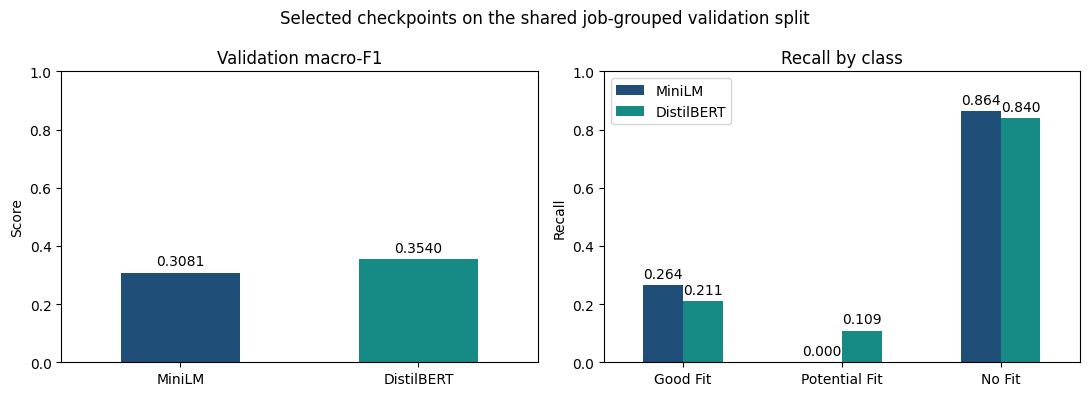

Figure saved to: /content/m3_comparison/model_comparison.png


In [42]:
import matplotlib.pyplot as plt

colors = ["#1F4E79", "#168A84"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

comparison_scores["Validation macro-F1"].plot.bar(
    ax=axes[0], color=colors, rot=0
)
axes[0].set_title("Validation macro-F1")
axes[0].set_xlabel("")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)
axes[0].bar_label(axes[0].containers[0], fmt="%.4f", padding=3)

comparison_scores[
    ["Good Fit recall", "Potential Fit recall", "No Fit recall"]
].T.plot.bar(ax=axes[1], color=colors, rot=0)

axes[1].set_title("Recall by class")
axes[1].set_xlabel("")
axes[1].set_ylabel("Recall")
axes[1].set_ylim(0, 1)
axes[1].set_xticklabels(LABELS, rotation=0)
axes[1].legend(title=None, loc="upper left")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.3f", padding=3)

fig.suptitle("Selected checkpoints on the shared job-grouped validation split")
fig.tight_layout()

comparison_figure_path = COMPARISON_DIR / "model_comparison.png"
fig.savefig(comparison_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {comparison_figure_path}")

In [43]:
mini = comparison_scores.loc["MiniLM"]
distil = comparison_scores.loc["DistilBERT"]

comparison_notes = f"""# Transformer Model Comparison

## Evaluation setup

Both models use the same dataset revision, job-grouped splits, label mapping,
512-token input policy, and training recipe. Checkpoints are selected by
validation macro-F1. Each model was trained once with seed 42.

## Findings

- MiniLM validation macro-F1: {mini['Validation macro-F1']:.4f}.
- DistilBERT validation macro-F1: {distil['Validation macro-F1']:.4f}.
- DistilBERT's absolute macro-F1 gain: {macro_f1_gain:.4f}.
- Good Fit recall changes from {mini['Good Fit recall']:.4f} to {distil['Good Fit recall']:.4f}.
- Potential Fit recall changes from {mini['Potential Fit recall']:.4f} to {distil['Potential Fit recall']:.4f}.
- No Fit recall changes from {mini['No Fit recall']:.4f} to {distil['No Fit recall']:.4f}.
- Training takes {mini['Training minutes']:.2f} and {distil['Training minutes']:.2f} minutes respectively.
- Peak PyTorch GPU allocations are {mini['Peak GPU GB']:.2f} and {distil['Peak GPU GB']:.2f} GB respectively.

## Interpretation

DistilBERT leads on validation macro-F1 and accuracy. MiniLM has higher Good Fit
recall. DistilBERT is the stronger candidate for further optimization under the
chosen primary metric, but both models still miss many suitable candidates.

The recorded times are single-run measurements, not a controlled inference-speed
benchmark. The official test set has not been evaluated for either transformer.

## Limitations and further investigation

Nearly all pairs require truncation, and only about 35-38% of original content
tokens remain on average. Class imbalance and lost input context are possible
contributors to the errors; their effects have not been isolated.

Test class-weighted loss and a documented section-aware input policy separately.
A direct comparison with the historical TF-IDF results also requires evaluating
that baseline approach under this same M3 split protocol.

See model_comparison.csv for the numeric comparison and model_comparison.png
for the figure. Detailed validation reports accompany each experiment.
"""

comparison_notes_path = COMPARISON_DIR / "comparison_notes.md"
comparison_notes_path.write_text(comparison_notes, encoding="utf-8")

print(f"Saved: {comparison_notes_path}")
print("Comparison findings and limitations recorded.")

Saved: /content/m3_comparison/comparison_notes.md
Comparison findings and limitations recorded.


In [44]:
assert json.loads(
    (DISTILBERT_REPORT_DIR / "reload_check.json").read_text()
)["passed"]

pd.testing.assert_frame_equal(
    pd.read_csv(COMPARISON_DIR / "model_comparison.csv"),
    comparison_df,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

distilbert_model_archive = Path("/content/distilbert_v1_model.zip")
distilbert_reports_archive = Path("/content/distilbert_v1_reports.zip")

model_files = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json"
]

with ZipFile(distilbert_model_archive, "w", ZIP_DEFLATED) as archive:
    for filename in model_files:
        archive.write(
            DISTILBERT_MODEL_EXPORT_DIR / filename,
            arcname=filename
        )

with ZipFile(distilbert_reports_archive, "w", ZIP_DEFLATED) as archive:
    for path in sorted(DISTILBERT_REPORT_DIR.iterdir()):
        if path.is_file():
            archive.write(path, arcname=path.name)

    for path in sorted(COMPARISON_DIR.iterdir()):
        if path.is_file():
            archive.write(path, arcname=f"comparison/{path.name}")

for path in [distilbert_reports_archive, distilbert_model_archive]:
    with ZipFile(path) as archive:
        assert archive.testzip() is None
        print(f"{path.name}: {len(archive.namelist())} files")
    print(f"Size: {path.stat().st_size / 1024**2:.2f} MiB")

files.download(str(distilbert_reports_archive))
files.download(str(distilbert_model_archive))

distilbert_v1_reports.zip: 11 files
Size: 0.10 MiB
distilbert_v1_model.zip: 4 files
Size: 235.75 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>